# EDA - Football Match Probability Prediction

Ce notebook presente une analyse exploratoire du dataset de prediction de matchs de football. Les donnees proviennent de l'API Kaggle et sont stockees dans `data/` (voir `README.md`). `train.csv` contient la cible `target`, `test.csv` contient les matchs a predire et `sample_submission.csv` donne le format de sortie.

## 1. Chargement reproductible

Les fichiers sont volumineux : on utilise des chemins relatifs au depot et une lecture pandas explicite.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

DATA_DIR = Path.cwd() / 'data'
train = pd.read_csv(DATA_DIR / 'train.csv', low_memory=False)
test = pd.read_csv(DATA_DIR / 'test.csv', low_memory=False)
submission = pd.read_csv(DATA_DIR / 'sample_submission.csv')
print('train:', train.shape)
print('test:', test.shape)
print('submission:', submission.shape)

train: (110938, 190)
test: (72711, 189)
submission: (72711, 4)


## 2. Structure et schema

Une ligne correspond a un match. Les variables couvrent les equipes, ligues, dates, statut coupe et historiques des dix derniers matchs. `target` est propre au train.

In [2]:
schema = pd.DataFrame({'dtype': train.dtypes.astype(str), 'missing': train.isna().sum(), 'missing_pct': (train.isna().mean() * 100).round(2), 'nunique': train.nunique(dropna=False)}).sort_values('missing_pct', ascending=False)
display(schema.head(20))
print('Colonnes propres au train:', sorted(set(train.columns) - set(test.columns)))
display(train['target'].value_counts(dropna=False).to_frame('count'))

,dtype,missing,missing_pct,nunique
away_team_history_coach_10,float64,27129,24.45,7937
home_team_history_coach_10,float64,26653,24.03,7892
away_team_history_coach_9,float64,26150,23.57,8045
home_team_history_coach_9,float64,25733,23.20,8003
away_team_history_coach_8,float64,25219,22.73,8145
home_team_history_coach_8,float64,24869,22.42,8151
away_team_history_coach_7,float64,24377,21.97,8304
home_team_history_coach_7,float64,23980,21.62,8266
away_team_history_coach_6,float64,23525,21.21,8441
home_team_history_coach_6,float64,23258,20.96,8386


Colonnes propres au train: ['target']


,count
target,
home,48113
away,35174
draw,27651


## 3. Qualite des donnees

On verifie les doublons, l'unicite des identifiants, les dates invalides et les colonnes constantes. Les historiques incomplets peuvent signaler qu'une equipe n'a pas dix matchs precedents.

In [3]:
print('Doublons train/test:', train.duplicated().sum(), test.duplicated().sum())
print('IDs uniques train/test:', train['id'].is_unique, test['id'].is_unique)
print('IDs train/test disjoints:', set(train['id']).isdisjoint(test['id']))
dates = pd.to_datetime(pd.concat([train['match_date'], test['match_date']]), errors='coerce')
print('Dates invalides:', dates.isna().sum())
print('Colonnes constantes:', int((train.nunique(dropna=False) <= 1).sum()))
display(schema[['missing', 'missing_pct']].head(15))

Doublons train/test: 0 0
IDs uniques train/test: True True
IDs train/test disjoints: True
Dates invalides: 0


Colonnes constantes: 0


,missing,missing_pct
away_team_history_coach_10,27129,24.45
home_team_history_coach_10,26653,24.03
away_team_history_coach_9,26150,23.57
home_team_history_coach_9,25733,23.20
away_team_history_coach_8,25219,22.73
home_team_history_coach_8,24869,22.42
away_team_history_coach_7,24377,21.97
home_team_history_coach_7,23980,21.62
away_team_history_coach_6,23525,21.21
home_team_history_coach_6,23258,20.96


## 4. Analyses adaptees au football

Le calendrier, les ligues, le statut coupe et la forme recente sont des axes pertinents. On examine aussi la couverture des historiques et le desequilibre de la cible.

C:\Users\chipi\AppData\Local\Temp\ipykernel_22272\278563226.py:1: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  all_matches = pd.concat([train.assign(split='train'), test.assign(split='test')], ignore_index=True)
C:\Users\chipi\AppData\Local\Temp\ipykernel_22272\278563226.py:2: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  all_matches['match_datetime'] = pd.to_datetime(all_matches['match_date'], errors='coerce')


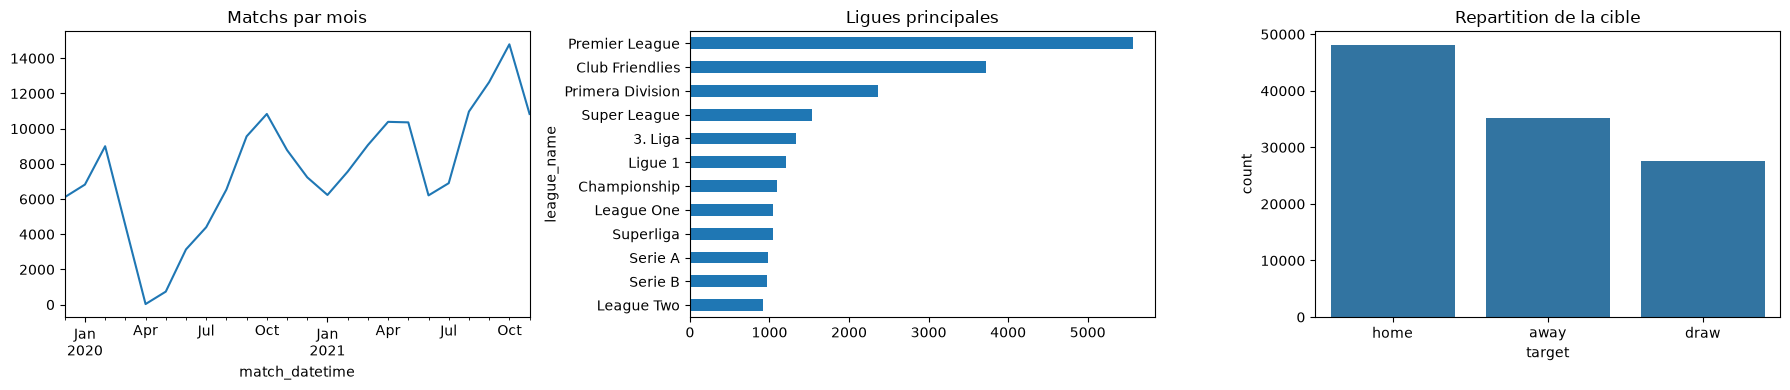

In [4]:
all_matches = pd.concat([train.assign(split='train'), test.assign(split='test')], ignore_index=True)
all_matches['match_datetime'] = pd.to_datetime(all_matches['match_date'], errors='coerce')
fig, axes = plt.subplots(1, 3, figsize=(18, 4))
all_matches.groupby(all_matches['match_datetime'].dt.to_period('M')).size().plot(ax=axes[0], title='Matchs par mois')
train['league_name'].value_counts().head(12).sort_values().plot.barh(ax=axes[1], title='Ligues principales')
sns.countplot(data=train, x='target', order=train['target'].value_counts().index, ax=axes[2])
axes[2].set_title('Repartition de la cible')
plt.tight_layout()

,count,mean,std,min,25%,50%,75%,max
home_matches_available,110938.0,9.35,2.01,0.0,10.0,10.0,10.0,10.0
away_matches_available,110938.0,9.31,2.07,0.0,10.0,10.0,10.0,10.0
home_recent_goals,109779.0,13.16,6.07,0.0,9.0,13.0,17.0,59.0
away_recent_goals,109712.0,13.13,6.05,0.0,9.0,13.0,17.0,57.0


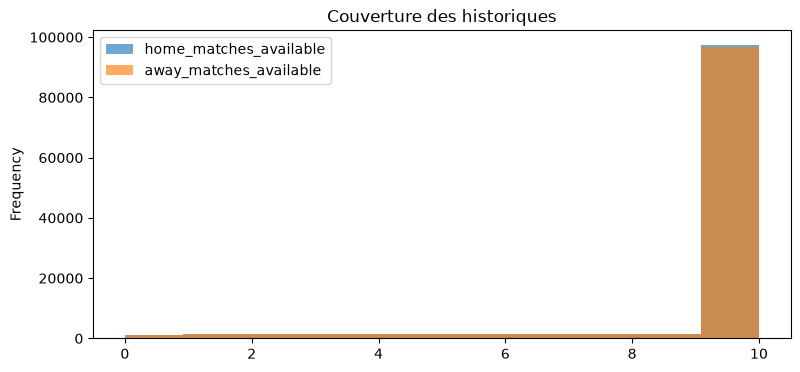

In [5]:
home_dates = [f'home_team_history_match_date_{i}' for i in range(1, 11)]
away_dates = [f'away_team_history_match_date_{i}' for i in range(1, 11)]
home_goals = [f'home_team_history_goal_{i}' for i in range(1, 11)]
away_goals = [f'away_team_history_goal_{i}' for i in range(1, 11)]
history = pd.DataFrame({'home_matches_available': train[home_dates].notna().sum(axis=1), 'away_matches_available': train[away_dates].notna().sum(axis=1), 'home_recent_goals': train[home_goals].sum(axis=1, min_count=1), 'away_recent_goals': train[away_goals].sum(axis=1, min_count=1)})
display(history.describe().T.round(2))
history[['home_matches_available', 'away_matches_available']].plot.hist(bins=11, alpha=.65, figsize=(9, 4), title='Couverture des historiques')
plt.show()

## 5. Controle du format de soumission

Les probabilites doivent etre dans [0, 1] et sommer a 1. Ce controle verifie l'alignement des identifiants avant prediction.

In [6]:
prob_cols = ['home', 'draw', 'away']
print('IDs submission = IDs test:', submission['id'].equals(test['id']))
print('Probabilites dans [0,1]:', ((submission[prob_cols] >= 0) & (submission[prob_cols] <= 1)).all().all())
print('Ecart maximal de somme a 1:', abs(submission[prob_cols].sum(axis=1) - 1).max())
display(submission[prob_cols].describe().T.round(3))

IDs submission = IDs test: True
Probabilites dans [0,1]: True
Ecart maximal de somme a 1: 0.0009999999999998899


,count,mean,std,min,25%,50%,75%,max
home,72711.0,0.333,0.0,0.333,0.333,0.333,0.333,0.333
draw,72711.0,0.333,0.0,0.333,0.333,0.333,0.333,0.333
away,72711.0,0.333,0.0,0.333,0.333,0.333,0.333,0.333


## Conclusions

Le dataset est une classification multiclasse temporelle sur des matchs de football. Les variables prometteuses sont la forme recente, les buts historiques, l'avantage domicile, la ligue, le contexte coupe et les effets de saison. Les historiques incomplets doivent etre accompagnes d'indicateurs de presence. Une validation chronologique est preferable a un split aleatoire pour eviter la fuite temporelle. Avant entrainement, il faudra encoder les categories, extraire les composantes des dates, agreger les historiques et verifier la stabilite train/test.